In [91]:
# Basic Imports
import os
import numpy as np
import math
import matplotlib.pyplot as plt
import cv2
import networkx as nx
from networkx.algorithms import community
from itertools import combinations

In [ ]:
# Load Datasets
def load_images(class_folder, img_size=(64, 64)):
    X = []
    VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

    for file in os.listdir(class_folder):
        if os.path.splitext(file)[1].lower() not in VALID_EXT:
            continue
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files
        
        X.append(img)

    return X

In [ ]:
X_train = load_images("Datasets/dataset_6")

### Phase 1: Grouping images into regions

In [ ]:
# Extract local features from every image - SIFT

sift = cv2.SIFT_create()

def extract_features(images):
    features = []

    for img in images:

        kp, des = sift.detectAndCompute(img, None)
        if des is None:
            print(f"Warning: No descriptors found for image index {len(features)}")
        features.append((kp, des))
    
        SHOW_KEYPOINTS = False  # True -> if you want to display keypoints extracted

        if SHOW_KEYPOINTS:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
            img2 = cv2.drawKeypoints(img_rgb, kp, None, color=(255,0,255), flags=0)
            plt.imshow(img2), plt.show()

    return features

In [ ]:
def compute_overlap_ratio(H, img_shape):
    h, w = img_shape[:2]
    corners = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    projected = cv2.perspectiveTransform(corners, H)
    
    # Compute intersection area with original image bounds
    rect1 = (0, 0, w, h)
    x,y,w2,h2 = cv2.boundingRect(projected.astype(np.int32))
    
    ix = max(0, min(rect1[2], x+w2) - max(rect1[0], x))
    iy = max(0, min(rect1[3], y+h2) - max(rect1[1], y))
    intersection = ix * iy
    union = w*h + w2*h2 - intersection
    
    return intersection / (w * h)  # what fraction of img1 is covered

In [96]:
# Match features between all image pairs 
# + BFMatcher using Hamming distance 
# + Lowe's ratio test to remove false/ambigious matches 
# + RANSAC for geometric verification
# + Build a similarity graph

def build_similarity_graph(features, images, ratio_threshold=0.65, min_inliers=150):
    G = nx.Graph()
    n_images = len(features)

    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

    total_matches = 0
    for i, j in combinations(range(len(images)), 2):
        img1, (kp1, des1) = images[i], features[i]
        img2, (kp2, des2) = images[j], features[j]
        
        # Skip if one image has no descriptors
        if des1 is None or des2 is None:
            continue

        # Use knnMatch to find the two best matches for each descriptor
        matches = bf.knnMatch(des1, des2, k=2)  # k=2 to get the two best matches

        # Apply Lowe's Ratio Test to filter out ambiguous matches
        filtered_matches = []
        for m, n in matches:
            if m.distance < ratio_threshold * n.distance:  # Lowe's ratio test
                filtered_matches.append(m)

        if len(filtered_matches) < 4: # Min 4 points needed for homography
            continue

        # Geometric Verification using RANSAC
        src_pts = np.float32([kp1[m.queryIdx].pt for m in filtered_matches]).reshape(-1,1,2)
        dest_pts = np.float32([kp2[m.trainIdx].pt for m in filtered_matches]).reshape(-1,1,2)

        H, mask = cv2.findHomography(src_pts, dest_pts, cv2.RANSAC, ransacReprojThreshold=3.0)

        if H is None:
            continue

        inliers = int(mask.sum()) # number of geometrically consistent matches

        # Build Graph Edge if enough matches
        overlap = compute_overlap_ratio(H, images[i].shape)
        
        if inliers >= min_inliers and overlap > 0.15:  # at least 15% overlap
            G.add_edge(i, j, weight=inliers, overlap=overlap, H=H, src=i, dst=j)
        
        total_matches += inliers
    
    print("Total matches: ",total_matches)
    print("Number of edges (similar pairs):", G.number_of_edges())

    return G

In [97]:
def display_graphs(graph):
        # Display edge weight distribution
        weights = [d['weight'] for u, v, d in graph.edges(data=True)]
        if len(weights) > 0:
                plt.hist(weights, bins=20)
                print(f"Min: {min(weights)}, Max: {max(weights)}, Mean: {np.mean(weights):.1f}")
                plt.xlabel("RANSAC Inlier Count")
                plt.ylabel("Number of Pairs")
                plt.title("Edge Weight Distribution")
                plt.show()
        else:
                print("No edges found")

        # Display simililarity graph (NetworkX)
        nx.draw(graph,
                pos=nx.circular_layout(graph),
                with_labels=True,
                node_color='violet', 
                edge_color='gray')
        plt.show()

Total matches:  31315
Number of edges (similar pairs): 20
Min: 260, Max: 3624, Mean: 1528.0


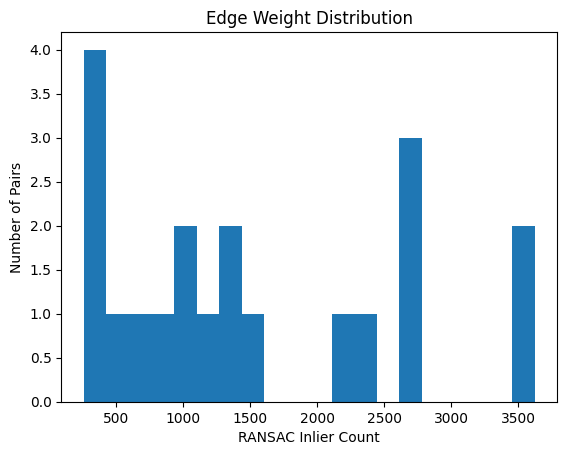

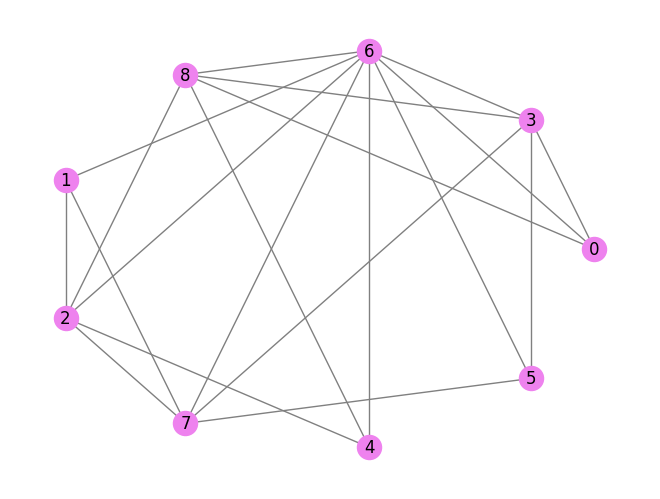

In [98]:
# Calling all functions for regional maps
features = extract_features(X_train)
graph = build_similarity_graph(features, X_train, min_inliers=150)
display_graphs(graph)

In [99]:
# Louvain-style community detection (greedy modularity) -> performs better than component detection 
communities = community.greedy_modularity_communities(graph, weight='weight')
for idx, comp in enumerate(communities):
    print(f"Group {idx}: images {sorted(comp)}")

Group 0: images [2, 4, 6, 8]
Group 1: images [1, 5, 7]
Group 2: images [0, 3]


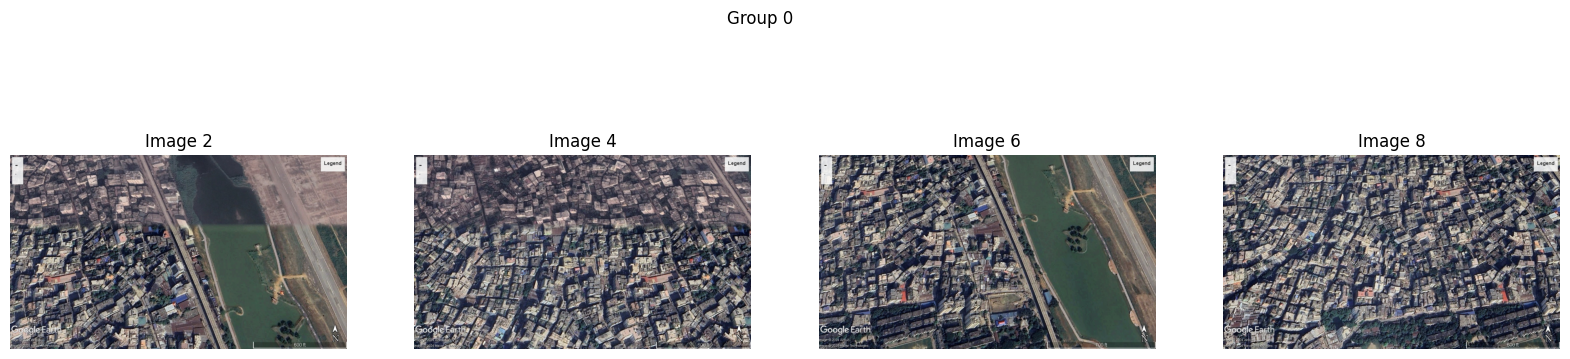

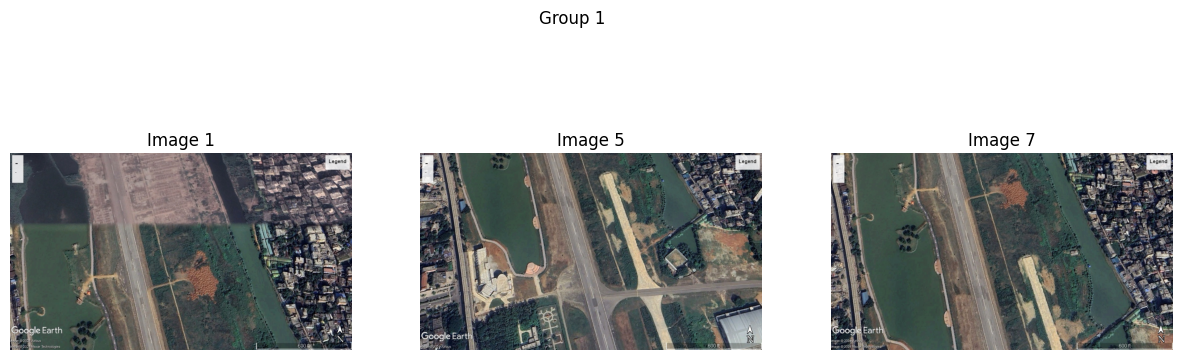

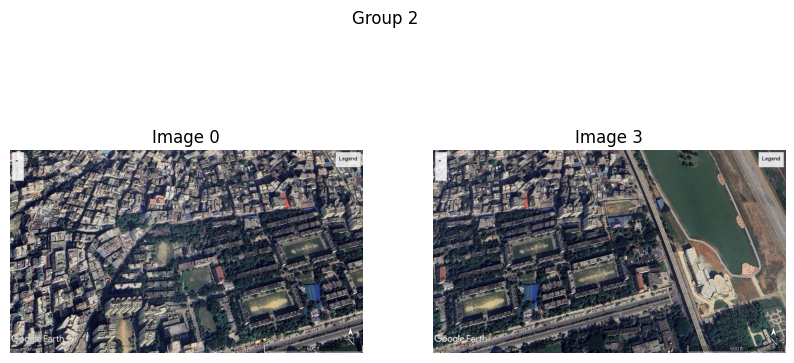

In [100]:
# Visualization of Community images
for group_idx, comp in enumerate(communities):
    images_in_group = sorted(comp)
    n = len(images_in_group)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1:
        axes = [axes]
    for ax, img_idx in zip(axes, images_in_group):
        ax.imshow(cv2.cvtColor(X_train[img_idx], cv2.COLOR_BGR2RGB))
        ax.set_title(f"Image {img_idx}")
        ax.axis('off')
    plt.suptitle(f"Group {group_idx}")
    plt.show()

### Phase 2: Image Stitching

In [101]:
# Decide order for stitching on the basis of Minimum Spanning Tree (MST)

def compute_stitching_order(graph, communities):
    stitching_order = [None] * len(communities)
    bfs_trees = [None] * len(communities)
    reference_nodes = [None] * len(communities)

    for group_idx, comp in enumerate(communities):
        nodes = sorted(comp)
        subgraph = graph.subgraph(nodes)
        
        mst = nx.maximum_spanning_tree(subgraph, weight='weight')
        
        # Pick the node with highest degree in MST as reference (most central or has most connecting edges)
        reference = max(mst.nodes(), key=lambda n: mst.degree(n))
        reference_nodes[group_idx] = reference
        print(f"Group {group_idx}: nodes={nodes}, reference image={reference}")
        
        # BFS order from reference = stitching order
        bfs_trees[group_idx] = nx.bfs_tree(mst, reference)
        stitching_order[group_idx] = list(bfs_trees[group_idx].nodes())
        print(f"  Stitching order: {stitching_order[group_idx]}")
        print(bfs_trees[group_idx])
        print()

    return stitching_order, bfs_trees, reference_nodes

In [102]:
def compute_homographies(graph, bfs_trees, reference_nodes, Communities):
    H_cumulative = {}

    for group_idx, comp in enumerate(Communities):
        ref_node = reference_nodes[group_idx]
        
        for current_node in bfs_trees[group_idx]:
            if current_node == ref_node:
                H_cumulative[ref_node] = np.eye(3)
            else:
                prev_node = next(bfs_trees[group_idx].predecessors(current_node))
                
                # Get the homography that maps current_node -> prev_node's space
                if graph.has_edge(prev_node, current_node):
                    H_pair = np.linalg.inv(graph[prev_node][current_node]['H'])
                elif graph.has_edge(current_node, prev_node):
                    H_pair = graph[current_node][prev_node]['H']
                else:
                    print(f"Warning: No edge between {prev_node} and {current_node}")
                    H_cumulative[current_node] = H_cumulative[prev_node]
                    continue
                edge_data = graph[prev_node][current_node] if graph.has_edge(prev_node, current_node) \
                else graph[current_node][prev_node]
                
                H_raw = edge_data['H']
                src, dst = edge_data['src'], edge_data['dst']

                # H maps src->dst; we want prev_node->current_node (to then invert for warping)
                if src == prev_node:
                    H_pair = np.linalg.inv(H_raw)  # H maps prev->current, invert to get current->prev
                else:
                    H_pair = H_raw  # H maps current->prev, already correct

                H_cumulative[current_node] = H_cumulative[prev_node] @ H_pair

    return H_cumulative

In [103]:
# Global canvas pre-computation
def calculate_canvas_size(nodes, images, H_cumulative):

    x_min_global, y_min_global = 0, 0
    x_max_global, y_max_global = 0, 0

    for node in nodes:
        h1, w1 = images[node].shape[:2]
        corners = np.float32([[0,0],[w1,0],[w1,h1],[0,h1]]).reshape(-1,1,2)
        warped_corners = cv2.perspectiveTransform(corners, H_cumulative[node])

        x_min, y_min = warped_corners[:,:,0].min(), warped_corners[:,:,1].min()
        x_max, y_max = warped_corners[:,:,0].max(), warped_corners[:,:,1].max()

        x_min_global = min(x_min_global, x_min)
        y_min_global = min(y_min_global, y_min)
        x_max_global = max(x_max_global, x_max)
        y_max_global = max(y_max_global, y_max)

    T_global = np.array([[1, 0, -x_min_global],
                        [0, 1, -y_min_global],
                        [0, 0,  1    ]])
    canvas_size = (int(x_max_global - x_min_global), int(y_max_global - y_min_global))
    return T_global, canvas_size


In [104]:
# Warp image 2 onto canvas
def warp_and_blend(img, H, T_cumulative, canvas_size):
    result = cv2.warpPerspective(img, T_cumulative@H, canvas_size)
    return result

In [105]:
# Applies group-wise warping and feather blending
def stitch_images(bfs_trees, images, H_cumulative, Communities,feather_blending = True):
    T_cumulative = [None] * len(Communities)
    stitched_maps = [None] * len(Communities)
    canvas_size = [None] * len(Communities)
    canvas = [None] * len(Communities)

    # Calculate Cumulative Transformation for each group
    for group_idx, comp in enumerate(Communities):
                T_cumulative[group_idx], canvas_size[group_idx] = calculate_canvas_size(bfs_trees[group_idx], images, H_cumulative)
                canvas[group_idx] = np.zeros((canvas_size[group_idx][1], canvas_size[group_idx][0], 3), dtype=np.uint8)

    # Warp and blend images region wise
    for group_idx, comp in enumerate(Communities):
        cumulative_weight = np.zeros(canvas_size[group_idx][::-1], dtype=np.float32)
        for current_node in bfs_trees[group_idx]:
                warped = warp_and_blend(images[current_node], H_cumulative[current_node], T_cumulative[group_idx], canvas_size[group_idx])
                mask = warped.any(axis=2) # non-black pixels
                if feather_blending:
                    mask_float = mask.astype(np.uint8)  # distanceTransform needs uint8
                    mask_weight = cv2.distanceTransform(mask_float, cv2.DIST_L2, 5)

                    mw = mask_weight[:,:,np.newaxis] # Conversion to 3D for computing with 3D image arrays
                    cumw = cumulative_weight[:,:,np.newaxis] # And 2D when working with 2D masks

                    new_canvas = (canvas[group_idx] * cumw + warped * mw) / (cumw + mw + 1e-8)
                    cumulative_weight = cumulative_weight + mask_weight # 2D + 2D
                    content_mask = (cumulative_weight + mask_weight) > 0 # 2D comparison
                    canvas[group_idx][content_mask] = new_canvas[content_mask].astype(np.uint8)
                else:
                    canvas[group_idx][mask] = warped[mask]

        stitched_maps[group_idx] = canvas[group_idx]

    # Display each stitched region
    for group_idx, canvas in enumerate(stitched_maps):
        plt.figure(figsize=(15,10))
        plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        plt.title(f"Group {group_idx}")
        plt.axis('off')
        plt.show()

    return stitched_maps

Group 0: nodes=[2, 4, 6, 8], reference image=8
  Stitching order: [8, 4, 6, 2]
DiGraph with 4 nodes and 3 edges

Group 1: nodes=[1, 5, 7], reference image=7
  Stitching order: [7, 1, 5]
DiGraph with 3 nodes and 2 edges

Group 2: nodes=[0, 3], reference image=0
  Stitching order: [0, 3]
DiGraph with 2 nodes and 1 edges



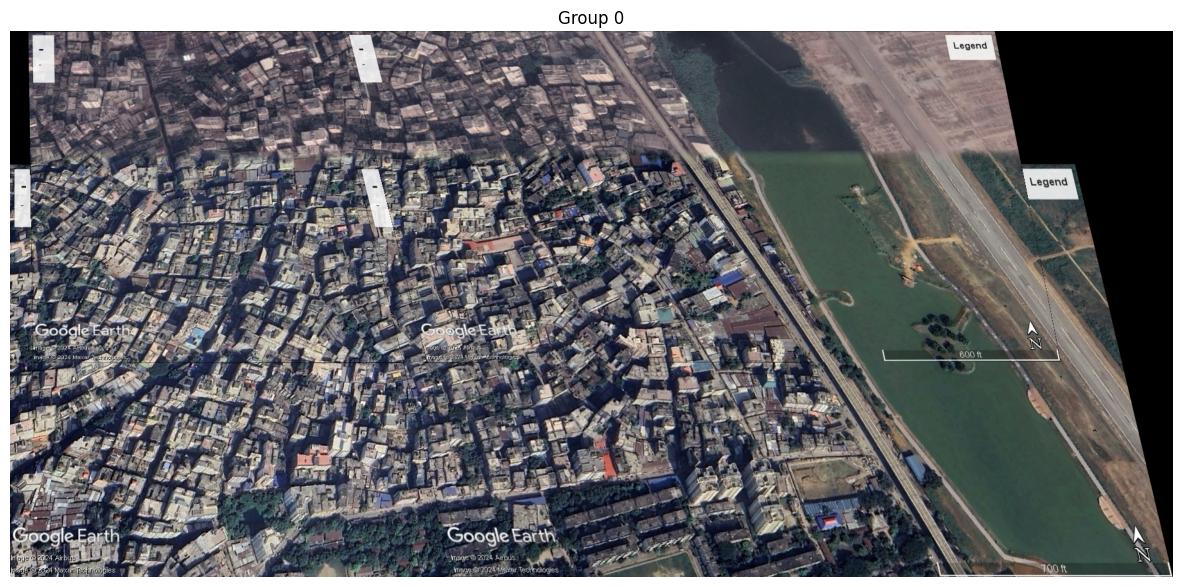

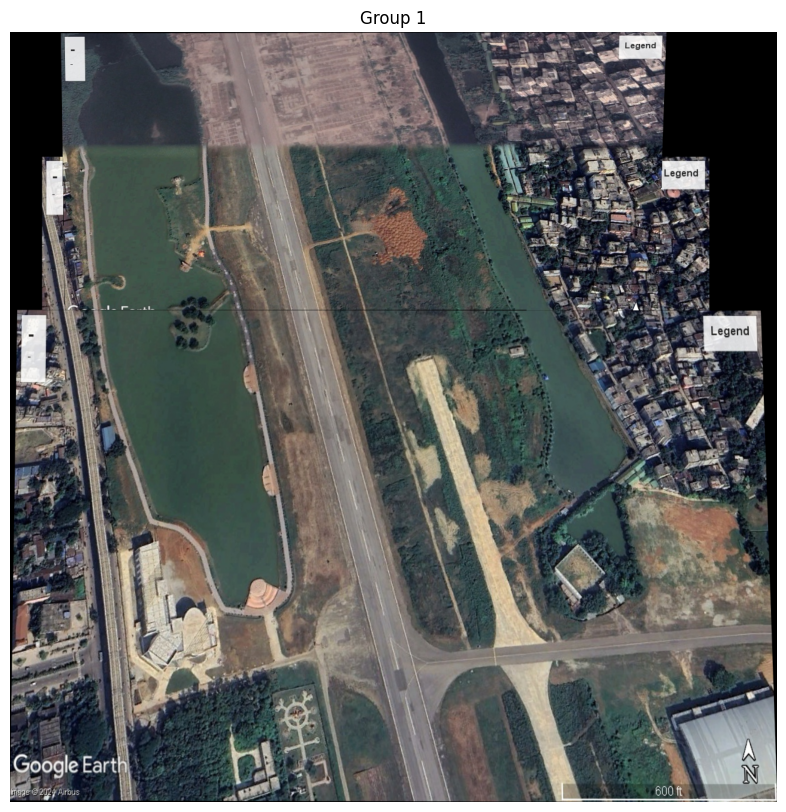

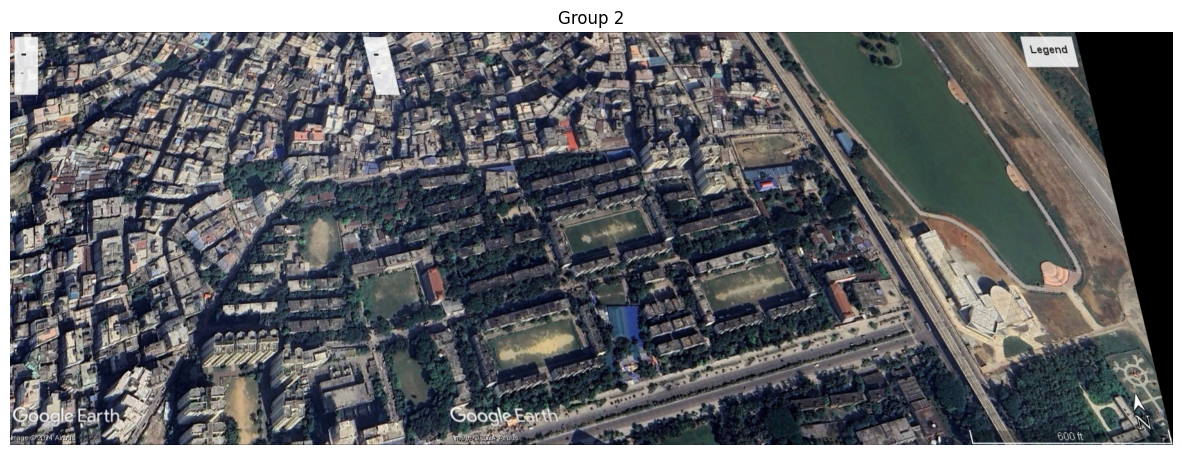

In [106]:
# Calling all functions for regional map stitching

stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, communities)
H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, communities)
regional_images = stitch_images(bfs_trees, X_train, H_cumulative, communities, feather_blending = False)

Total matches:  4817
Number of edges (similar pairs): 3
Min: 116, Max: 4471, Mean: 1605.7


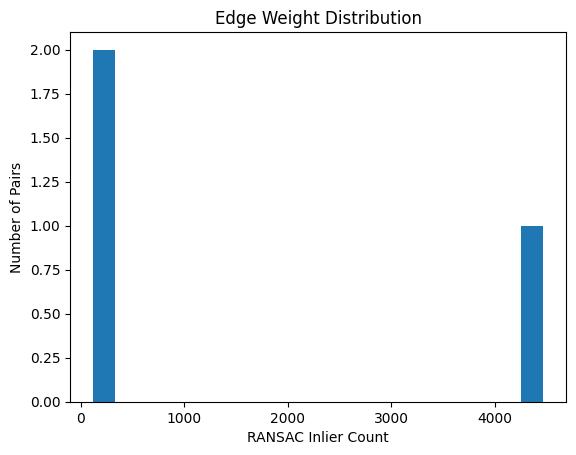

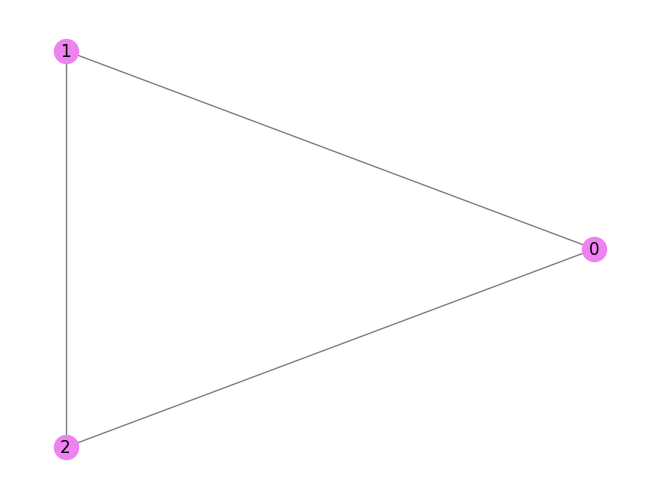

In [107]:
# Stitch regional maps into global map
features = extract_features(regional_images)
graph = build_similarity_graph(features, regional_images, min_inliers=70)
# print(graph.degree(0))
display_graphs(graph)
global_communities = [frozenset(range(len(regional_images)))] # Treat all regional maps as one community

Group 0: nodes=[0, 1, 2], reference image=2
  Stitching order: [2, 0, 1]
DiGraph with 3 nodes and 2 edges



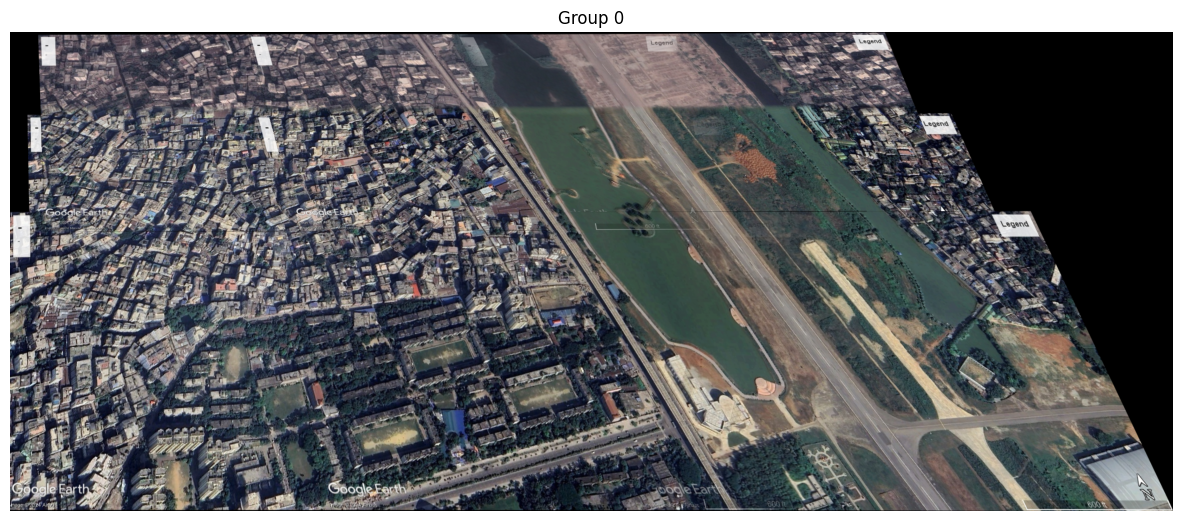

In [108]:
stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, global_communities)
H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, global_communities)
global_image = stitch_images(bfs_trees, regional_images, H_cumulative, global_communities)

### Phase 3: Convert to 2D map

In [109]:
def needs_rectification(image, val = False):
    h, w = image.shape[:2]
    cx, cy = w // 2, h // 2  # Centre coordinates

    y, x = np.indices((h, w)) # Generates two 2D grids (y and x) representing the pixel coordinates
    dist = np.sqrt((x - cx)**2 + (y - cy)**2) # Calculates the Euclidean distance from every pixel to center (cx, cy)
    weights = dist / dist.max() # farther from centre means greater weight

    black_mask = (image == 0).all(axis=2) 
    result = black_mask.astype(np.float32) * weights

    weighted_black = np.sum(result)  # sum of weights where pixels are black
    total_weight = np.sum(weights)   # total possible weight across all pixels (if they weren't multiplied by zero for non-black pixels)
    pixel_ratio = (weighted_black / total_weight) * 100

    if val:
        if pixel_ratio > 30:
            return True
        else:
            return False
    else:
        if pixel_ratio > 15:
            return True
        else:
            return False

In [110]:
def detect_boundary(image):
    mask = (image > 0).any(axis=2).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    largest = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(largest)
    
    # Dynamically adjust epsilon to force exactly 4 points
    peri = cv2.arcLength(hull, True)
    for epsilon_factor in np.linspace(0.01, 0.1, 100):
        approx = cv2.approxPolyDP(hull, epsilon_factor * peri, True)
        if len(approx) == 4:
            break
            
    # If 4 points aren't found, use a bounding box or take the first 4
    if len(approx) != 4:
        rect = cv2.minAreaRect(hull)
        approx = cv2.boxPoints(rect).astype(int)

    pts = approx.reshape(4, 2)
    
    # Sort points 
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)
    ordered_pts = np.zeros((4, 2), dtype="float32")
    ordered_pts[0] = pts[np.argmin(s)]       # top-left
    ordered_pts[2] = pts[np.argmax(s)]       # bottom-right
    ordered_pts[1] = pts[np.argmin(diff)]    # top-right
    ordered_pts[3] = pts[np.argmax(diff)]    # bottom-left

    side1 = math.dist(ordered_pts[0], ordered_pts[1])
    side2 = math.dist(ordered_pts[1], ordered_pts[2])
    
    h, w = sorted([side1, side2])
    aspect_ratio = h / float(w)

    return [largest, ordered_pts, aspect_ratio]


In [111]:
def apply_homography(image, rectangle):
    cnt = rectangle[0]
    pts = rectangle[1]
    aspect_ratio = rectangle[2]

    # Order points
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)

    tl = pts[np.argmin(s)]       # Top-left has smallest sum
    br = pts[np.argmax(s)]       # Bottom-right has largest sum
    tr = pts[np.argmin(diff)]    # Top-right has smallest difference
    bl = pts[np.argmax(diff)]    # Bottom-left has largest difference

    src_pts = np.array([tl, tr, br, bl], dtype="float32")

    # Calculate destination dimensions based on aspect_ratio
    width_top = np.linalg.norm(tr - tl)
    width_bottom = np.linalg.norm(br - bl)
    max_w = int(max(width_top, width_bottom))

    height_left = np.linalg.norm(bl - tl)
    height_right = np.linalg.norm(br - tr)
    max_h = int(max(height_left, height_right))

    dst_pts = np.array([
        [0, 0],
        [max_w - 1, 0],
        [max_w - 1, max_h - 1],
        [0, max_h - 1]], dtype="float32")

    # Apply transformation
    H = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(image, H, (max_w, max_h))
    
    return warped

In [112]:
def orthorectify1(image, max_retries=3):
    print(needs_rectification(image)) 
    if not needs_rectification(image):  # black boundary pixel check
        return image
    
    boundary = detect_boundary(image)
    rectified = apply_homography(image, boundary)
    
    if not needs_rectification(rectified, val=True):  # black pixel check again
        return rectified
        
    return image  # return original if all attempts fail

True


True

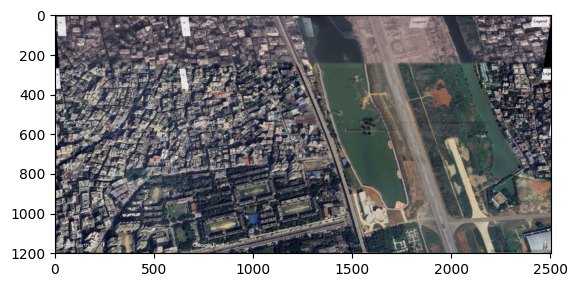

In [113]:
topdown_image = orthorectify1(global_image[0])
plt.imshow(cv2.cvtColor(topdown_image, cv2.COLOR_BGR2RGB))
cv2.imwrite('topdown_image.png', topdown_image)